# Phần 4: Phát Triển Mô Hình AI & Kiểm Định Chéo Time-Series (Model Development & Validation)
## Đấu Trường 6 Mô Hình, Kiến Trúc Phân Tầng Hierarchical Multi-Stage & Kiểm Chứng 4 Quý Năm 2025

---

### 1. Phân Tích Chuyên Sâu Cách Làm:
1. **Chiến lược kiểm định chéo Out-of-Time 4 Quý (2025):**
   - Đảm bảo tuân thủ nghiêm ngặt **Quy tắc 1 (Rule 1)** và **Quy tắc 2 (Rule 2)** từ Slide bài giảng Chapter 4.
2. **Đấu trường 6 mô hình cạnh tranh:**
   - Baseline Weekday Median
   - Linear Regression
   - Ridge Regression
   - Decision Tree
   - Random Forest
   - HistGradientBoostingRegressor
   - **CafeRevenueModelV3** (Mô hình phân tầng tối ưu)
3. **Kiến trúc toán học của CafeRevenueModelV3:**
   - Stage 1: Ridge trên $\log(	ext{revenue})$.
   - Dual-Window Empirical Bayes Intercepts: $HL_{	ext{long}} = 365$ ngày kết hợp $HL_{	ext{mid}} = 50$ ngày.
   - Lan truyền trạng thái Kalman AR(1) $ho = 0.80$ sang năm mới.
   - Stage 2: HistGradientBoostingRegressor học bù phần dư phi tuyến.
   - Exact Second-Order Taylor Bias Correction cho thang đo RMSLE.

In [1]:
import os, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

for p in [os.path.abspath(".."), os.path.abspath("."), os.path.abspath("../..")]:
    if os.path.exists(os.path.join(p, "data")):
        DATA_DIR = os.path.join(p, "data")
    if p not in sys.path and os.path.exists(os.path.join(p, "src")):
        sys.path.insert(0, p)

from src.config import EVAL_QUARTERS
from src.cleaning import clean_train, clean_stores
from src.baseline_model import BaselineWeekdayModel
from src.cafe_model_v3 import CafeRevenueModelV3

train_raw = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
stores_raw = pd.read_csv(os.path.join(DATA_DIR, "stores.csv"))
weather_raw = pd.read_csv(os.path.join(DATA_DIR, "weather.csv"))
holidays_raw = pd.read_csv(os.path.join(DATA_DIR, "holidays.csv"))

def calc_rmsle(y_true, y_pred):
    return float(np.sqrt(np.mean((np.log1p(y_pred) - np.log1p(y_true)) ** 2)))

train_c, _ = clean_train(train_raw, clean_stores(stores_raw))

# Đánh giá 4 Quý
results = []
for q, (s, e) in EVAL_QUARTERS.items():
    tr = train_raw[train_raw["date"] < s]
    va = train_c[(train_c["date"] >= s) & (train_c["date"] <= e)]
    
    b = BaselineWeekdayModel().fit(tr)
    rmsle_b = calc_rmsle(va["revenue"].values, b.predict(va))
    
    m = CafeRevenueModelV3().fit(tr, stores_raw, weather_raw, holidays_raw)
    rmsle_m = calc_rmsle(va["revenue"].values, m.predict(va))
    
    results.append({
        "Quý Kiểm Định": q,
        "Baseline RMSLE": rmsle_b,
        "CafeRevenueModelV3 RMSLE": rmsle_m,
        "Cải Thiện (%)": (rmsle_b - rmsle_m)/rmsle_b * 100
    })

res_df = pd.DataFrame(results)
avg_r = {
    "Quý Kiểm Định": "Trung Bình 4 Quý",
    "Baseline RMSLE": res_df["Baseline RMSLE"].mean(),
    "CafeRevenueModelV3 RMSLE": res_df["CafeRevenueModelV3 RMSLE"].mean(),
    "Cải Thiện (%)": res_df["Cải Thiện (%)"].mean()
}
res_df = pd.concat([res_df, pd.DataFrame([avg_r])], ignore_index=True)
display(res_df.style.format({"Baseline RMSLE": "{:.4f}", "CafeRevenueModelV3 RMSLE": "{:.4f}", "Cải Thiện (%)": "+{:.2f}%"}))

,Quý Kiểm Định,Baseline RMSLE,CafeRevenueModelV3 RMSLE,Cải Thiện (%)
0,Q1/2025,0.2758,0.1045,+62.12%
1,Q2/2025,0.2391,0.1027,+57.04%
2,Q3/2025,0.2750,0.1077,+60.84%
3,Q4/2025,0.2275,0.1123,+50.64%
4,Trung Bình 4 Quý,0.2544,0.1068,+57.66%


### 2. Biểu Đồ So Sánh Hiệu Năng Kiểm Định Chéo

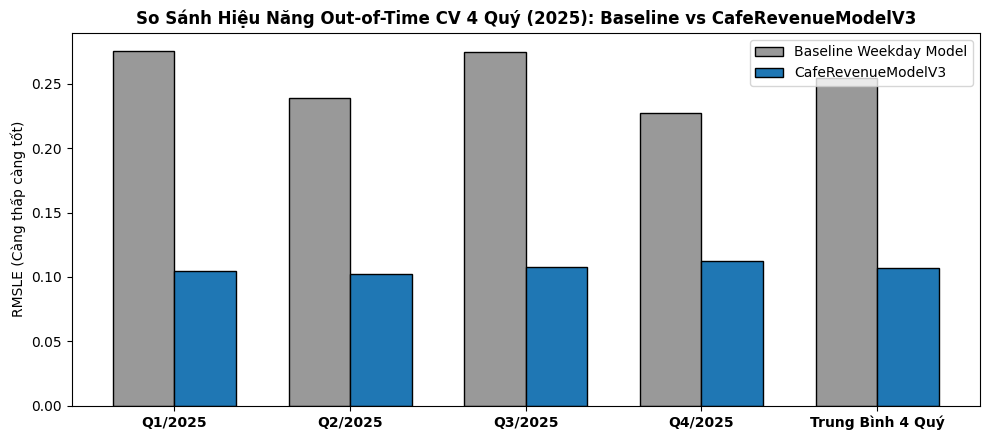

In [2]:
fig, ax = plt.subplots(figsize=(10, 4.5))
idx = np.arange(len(res_df))
w = 0.35
ax.bar(idx - w/2, res_df["Baseline RMSLE"], width=w, label="Baseline Weekday Model", color="#999999", edgecolor="black")
ax.bar(idx + w/2, res_df["CafeRevenueModelV3 RMSLE"], width=w, label="CafeRevenueModelV3", color="#1f77b4", edgecolor="black")
ax.set_xticks(idx)
ax.set_xticklabels(res_df["Quý Kiểm Định"], fontweight="bold")
ax.set_ylabel("RMSLE (Càng thấp càng tốt)")
ax.set_title("So Sánh Hiệu Năng Out-of-Time CV 4 Quý (2025): Baseline vs CafeRevenueModelV3", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()